In [1]:
from parametric_coupling import DesignHelper
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd
import scienceplots
plt.style.use(['science', 'notebook', 'no-latex'])

In [2]:
dh = DesignHelper(
    alpha_inductance = 0.0
)

# Cálculo de parámetros objetivo para el transmon

In [3]:
frequency_window_GHz = np.linspace(4, 8)
transmon_ratio_values = np.linspace(50, 100)
EJ, EC, Ic, C, Lj, alpha = [], [], [], [], [], []

for freq in frequency_window_GHz:
    rEJ, rEC, rIc, rC, rLj, rA = [], [], [], [], [], []
    for ratio in transmon_ratio_values:
        res = dh.compute_EJ_EC_from_frequency_ratio(freq, ratio)
        ej, ec = res['EJ'], res['EC']
        rEJ.append(ej.magnitude)                                    # GHz
        rEC.append(ec.magnitude)                                    # GHz
        rIc.append(dh.EJ_to_Ic(ej).magnitude)                       # nA
        rC.append(dh.EC_to_C(ec).magnitude)                         # fF
        rLj.append(dh.EJ_to_Lj(ej).magnitude)                       # nH
        rA.append(dh.compute_anharmonicity(ec, exact_EJ=ej).to("MHz").magnitude)  # MHz (exact f12-f01)
    EJ.append(rEJ); EC.append(rEC); Ic.append(rIc); C.append(rC); Lj.append(rLj); alpha.append(rA)

EJ, EC, Ic, C, Lj, alpha = (np.array(a) for a in (EJ, EC, Ic, C, Lj, alpha))


Text(0, 0.5, '$E_J/E_C$')

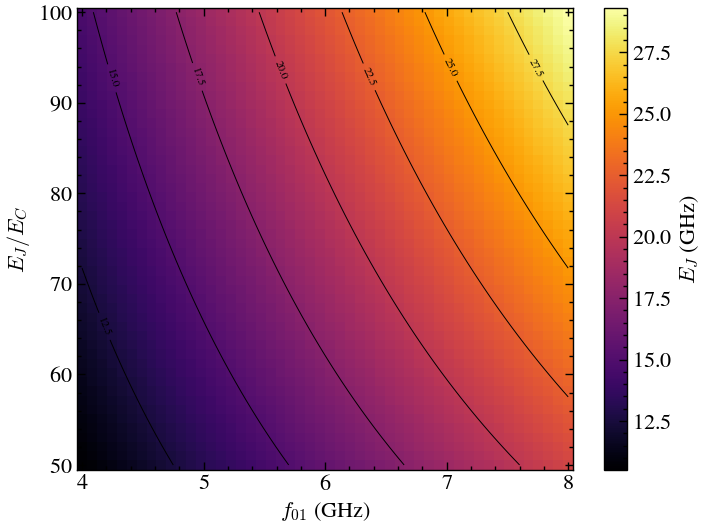

In [4]:
im = plt.pcolormesh(frequency_window_GHz, transmon_ratio_values, EJ.T, shading='auto', cmap = 'inferno')
plt.colorbar(im, label='$E_J$ (GHz)')

cs = plt.contour(frequency_window_GHz, transmon_ratio_values, EJ.T, colors='k', linewidths=0.7)
plt.clabel(cs, inline=True, fontsize=8, fmt='%.1f')

plt.xlabel('$f_{01}$ (GHz)')
plt.ylabel('$E_J/E_C$')


Text(0, 0.5, '$E_J/E_C$')

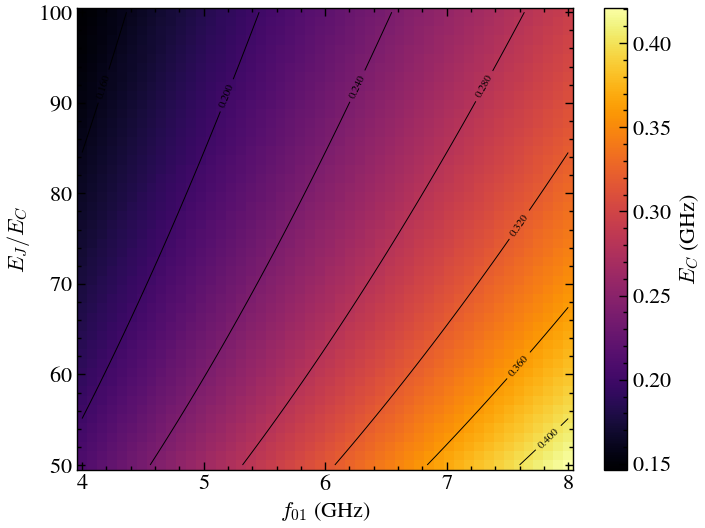

In [5]:
im = plt.pcolormesh(frequency_window_GHz, transmon_ratio_values, EC.T, shading='auto', cmap = 'inferno')
plt.colorbar(im, label='$E_C$ (GHz)')

cs = plt.contour(frequency_window_GHz, transmon_ratio_values, EC.T, colors='k', linewidths=0.7)
plt.clabel(cs, inline=True, fontsize=8, fmt='%.3f')

plt.xlabel('$f_{01}$ (GHz)')
plt.ylabel('$E_J/E_C$')


Text(0, 0.5, '$E_J/E_C$')

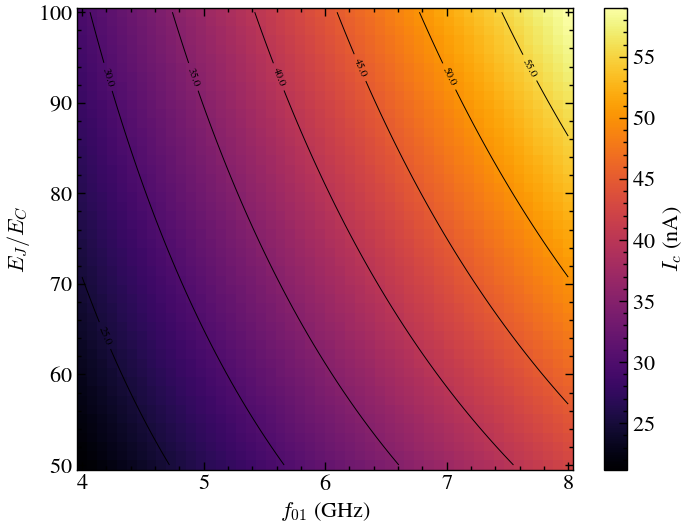

In [6]:
im = plt.pcolormesh(frequency_window_GHz, transmon_ratio_values, Ic.T, shading='auto', cmap = 'inferno')
plt.colorbar(im, label='$I_c$ (nA)')

cs = plt.contour(frequency_window_GHz, transmon_ratio_values, Ic.T, colors='k', linewidths=0.7)
plt.clabel(cs, inline=True, fontsize=8, fmt='%.1f')

plt.xlabel('$f_{01}$ (GHz)')
plt.ylabel('$E_J/E_C$')


Text(0, 0.5, '$E_J/E_C$')

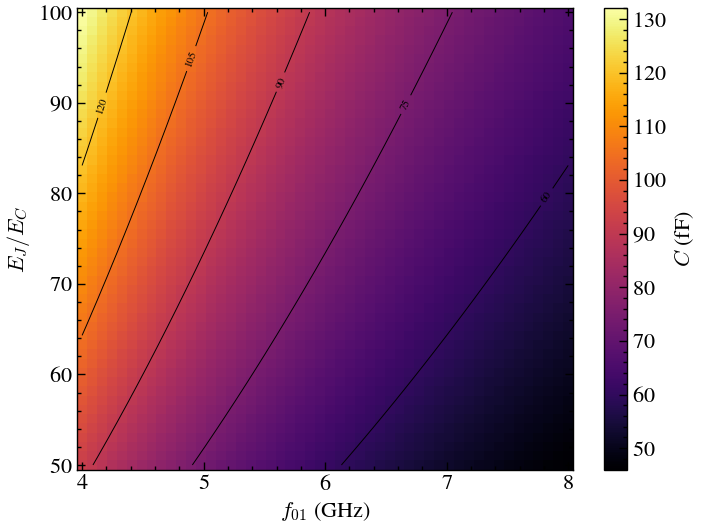

In [7]:
im = plt.pcolormesh(frequency_window_GHz, transmon_ratio_values, C.T, shading='auto', cmap = 'inferno')
plt.colorbar(im, label='$C$ (fF)')

cs = plt.contour(frequency_window_GHz, transmon_ratio_values, C.T, colors='k', linewidths=0.7)
plt.clabel(cs, inline=True, fontsize=8, fmt='%.0f')

plt.xlabel('$f_{01}$ (GHz)')
plt.ylabel('$E_J/E_C$')

Text(0.5, 0.98, 'Transmon design parameters vs $f_{01}$ and $E_J/E_C$')

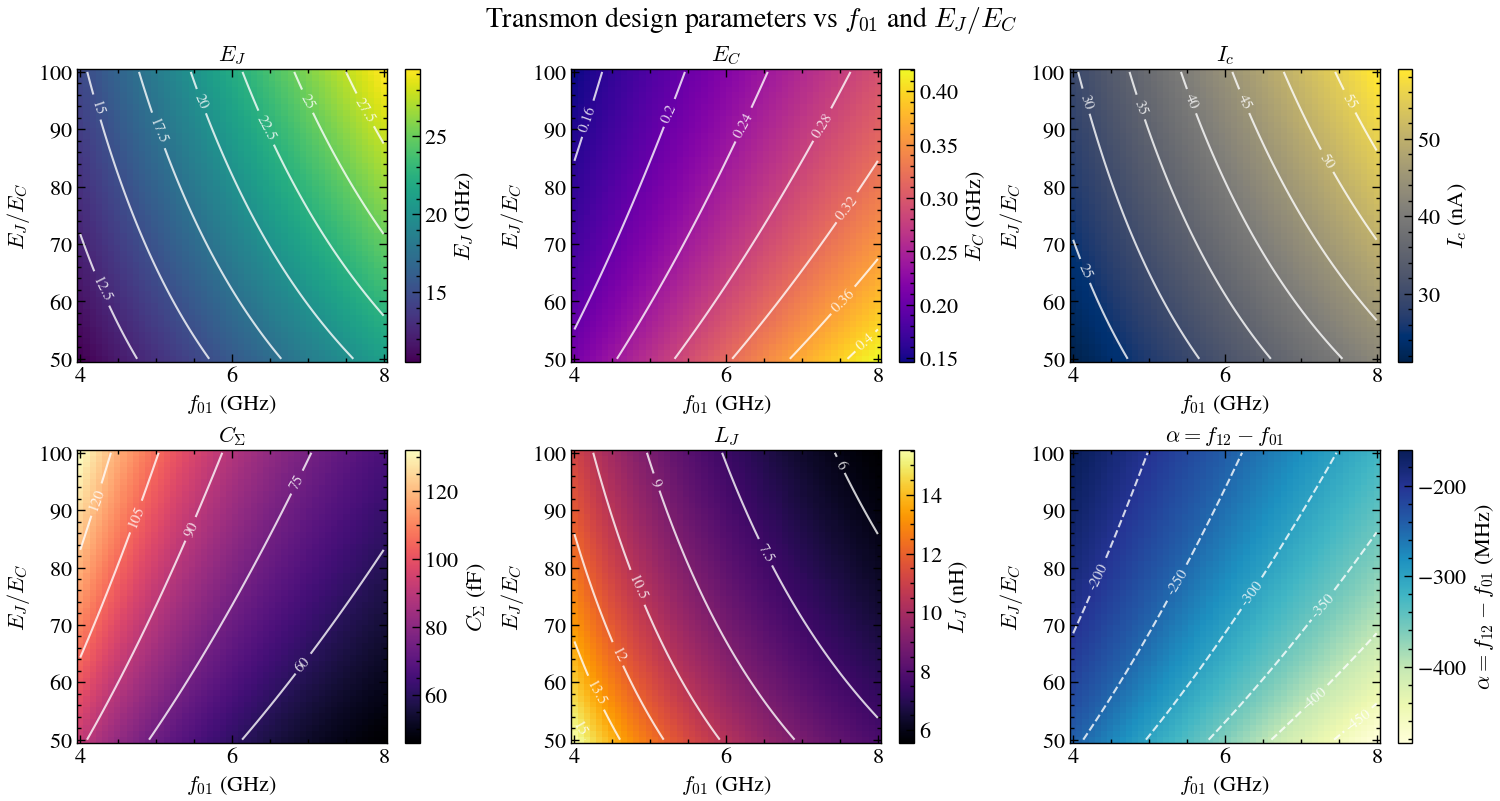

In [8]:
X, Y = frequency_window_GHz, transmon_ratio_values

panels = [
    ("$E_J$",         EJ,    "GHz", "viridis"),
    ("$E_C$",         EC,    "GHz", "plasma"),
    ("$I_c$",         Ic,    "nA",  "cividis"),
    ("$C_\\Sigma$",   C,     "fF",  "magma"),
    ("$L_J$",         Lj,    "nH",  "inferno"),
    ("$\\alpha = f_{12}-f_{01}$", alpha, "MHz", "YlGnBu"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for ax, (label, Z, unit, cmap) in zip(axes.flat, panels):
    im = ax.pcolormesh(X, Y, Z.T, cmap=cmap, shading="auto")   # .T: Z is (freq, ratio)
    cs = ax.contour(X, Y, Z.T, colors="w", linewidths=1.5, alpha=0.8)   # was 0.6
    ax.clabel(cs, inline=True, fontsize=11, fmt="%.3g")                   # was 7

    fig.colorbar(im, ax=ax, label=f"{label} ({unit})")
    ax.set_xlabel("$f_{01}$ (GHz)")
    ax.set_ylabel("$E_J/E_C$")
    ax.set_title(label)
fig.suptitle("Transmon design parameters vs $f_{01}$ and $E_J/E_C$", fontsize=20)

# plt.savefig('/home/ruiz/Documents/thesis/figures/export/transmon_parameters.png', dpi = 500)

# Análisis de acoplamientos a primeros vecinos

In [9]:
# computes the C matrix of a system of N identical transmons which have a coupling capacitance rho times their shunt capacitance to ground

def first_neighbour_matrix(N, rho, pbc=False):
    """Maxwell capacitance matrix (in units of the shunt capacitance C_g) for a
    1D chain of N identical transmons, each nearest-neighbour pair coupled by a
    capacitance rho * C_g.

    pbc=False : open chain  -- end islands have 1 neighbour
    pbc=True  : periodic ring -- every island has 2 neighbours; islands 0 and
                N-1 are also coupled

    Every island keeps its full C_g to ground, so every row sums to 1.
    """
    off = -rho * np.ones(N - 1)
    C = np.diag(off, 1) + np.diag(off, -1)          # nearest-neighbour couplings
    if pbc and N > 2:
        C[0, -1] = C[-1, 0] = -rho                  # close the ring
    np.fill_diagonal(C, 1.0 - C.sum(axis=1))        # diag_i = C_g + (#neighbours_i)*rho
    return C



/tmp/ipykernel_43279/3052348620.py:18: RuntimeWarning: invalid value encountered in divide
  r21 = d2 / d1[:len(d2)]        # 2nd off-diagonal / 1st off-diagonal


Text(0.5, 0.98, 'Inverse capacitance-matrix off-diagonal ratios  (N=7, OBC)')

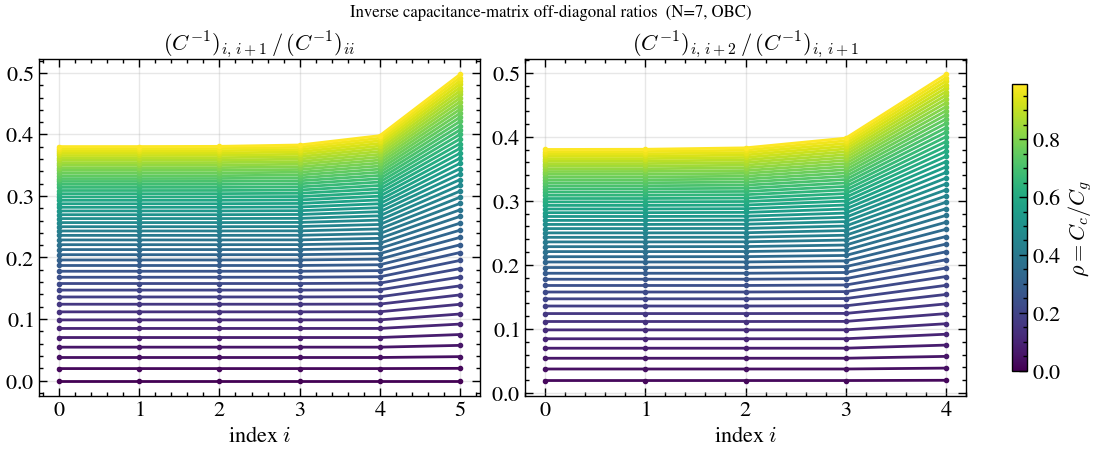

In [10]:
import matplotlib as mpl
N = 7
rho_values = np.linspace(0.0, 0.99)
PBC = False

cmap = mpl.cm.viridis
norm = mpl.colors.Normalize(vmin=rho_values.min(), vmax=rho_values.max())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

for rho in rho_values:
    Cinv = np.linalg.inv(first_neighbour_matrix(N, rho, PBC))
    d0 = np.diag(Cinv)
    d1 = np.diag(Cinv, 1)
    d2 = np.diag(Cinv, 2)

    r10 = d1 / d0[:len(d1)]        # 1st off-diagonal / diagonal
    r21 = d2 / d1[:len(d2)]        # 2nd off-diagonal / 1st off-diagonal

    color = cmap(norm(rho))
    axes[0].plot(np.arange(len(r10)), r10, color=color, marker="o", ms=3)
    axes[1].plot(np.arange(len(r21)), r21, color=color, marker="o", ms=3)

axes[0].set_title(r"$(C^{-1})_{i,\,i+1}\,/\,(C^{-1})_{ii}$")
axes[1].set_title(r"$(C^{-1})_{i,\,i+2}\,/\,(C^{-1})_{i,\,i+1}$")
for ax in axes:
    ax.set_xlabel("index $i$")
    ax.grid(alpha=0.3)

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=axes, label=r"$\rho = C_c / C_g$", shrink=0.85)
fig.suptitle(f"Inverse capacitance-matrix off-diagonal ratios  (N={N}, {'PBC' if PBC else 'OBC'})")


/tmp/ipykernel_43279/1453094996.py:12: RuntimeWarning: invalid value encountered in scalar divide
  r21.append(d2[i_fix] / d1[i_fix])       # 2nd off-diag / 1st off-diag


Text(0.5, 1.0, 'Off-diagonal ratios vs $\\rho$  (N=10, OBC, $i=7$)')

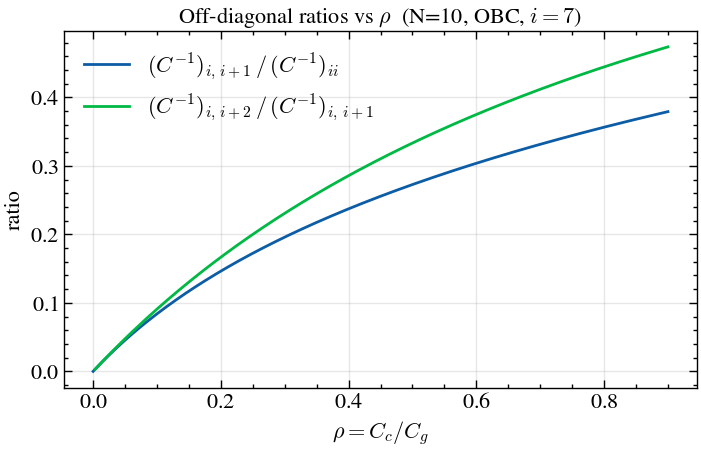

In [11]:
import matplotlib as mpl
N = 10
PBC = False
# i_fix = N // 2 - 1          # a central ("bulk") index; try 0 for the edge
i_fix= 7
rho_grid = np.linspace(0.0, 0.9, 300)
r10, r21 = [], []
for rho in rho_grid:
    Cinv = np.linalg.inv(first_neighbour_matrix(N, rho, PBC))
    d0 = np.diag(Cinv); d1 = np.diag(Cinv, 1); d2 = np.diag(Cinv, 2)
    r10.append(d1[i_fix] / d0[i_fix])       # 1st off-diag / diagonal
    r21.append(d2[i_fix] / d1[i_fix])       # 2nd off-diag / 1st off-diag

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.plot(rho_grid, r10, label=r"$(C^{-1})_{i,\,i+1}\,/\,(C^{-1})_{ii}$")
ax.plot(rho_grid, r21, label=r"$(C^{-1})_{i,\,i+2}\,/\,(C^{-1})_{i,\,i+1}$")
ax.set_xlabel(r"$\rho = C_c / C_g$")
ax.set_ylabel("ratio")
ax.grid(alpha=0.3)
ax.legend()
ax.set_title(f"Off-diagonal ratios vs $\\rho$  (N={N}, {'PBC' if PBC else 'OBC'}, $i={i_fix}$)")


Text(0.5, 1.0, 'How large can the coupling capacitance get before NNN hopping matters')

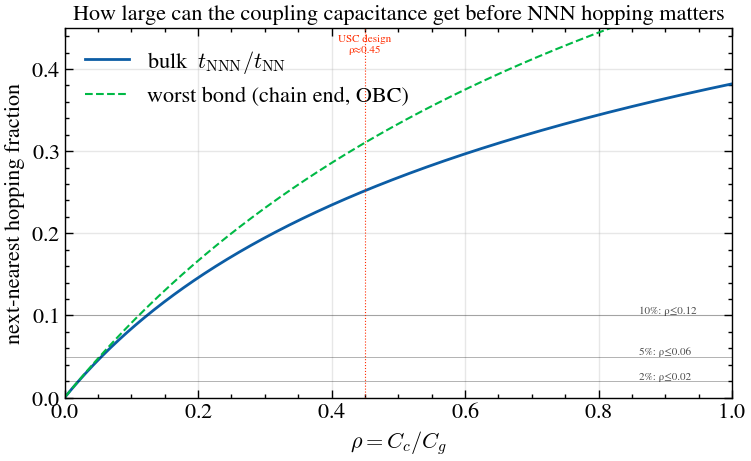

In [12]:
def z_ratio(rho):
    """bulk t_NNN / t_NN  =  (C^-1)_{i,i+2} / (C^-1)_{i,i+1}"""
    return ((1 + 2*rho) - np.sqrt(1 + 4*rho)) / (2*rho)

rho = np.linspace(1e-3, 1.0, 400)

# worst bond anywhere in a finite OBC chain (deviation is N-independent for N>=4)
def worst_bond_ratio(rho, N=8):
    Ci = np.linalg.inv(first_neighbour_matrix(N, rho, False))
    d1, d2 = np.diag(Ci, 1), np.diag(Ci, 2)
    return np.max(d2 / d1[:len(d2)])

worst = np.array([worst_bond_ratio(r) for r in rho])

fig, ax = plt.subplots(figsize=(7.5, 4.6), constrained_layout=True)
ax.plot(rho, z_ratio(rho), lw=2, label=r"bulk  $t_{\rm NNN}/t_{\rm NN}$")
ax.plot(rho, worst, "--", lw=1.5, label="worst bond (chain end, OBC)")

for tol, lbl in [(0.02, "2%"), (0.05, "5%"), (0.10, "10%")]:
    ax.axhline(tol, color="k", lw=0.6, alpha=0.35)
    rmax = rho[np.argmin(np.abs(z_ratio(rho) - tol))]
    ax.annotate(f"{lbl}: ρ≤{rmax:.2f}", (0.86, tol), fontsize=8, va="bottom", alpha=0.7)

ax.axvline(0.45, color="C3", lw=0.8, ls=":")
ax.annotate("USC design\nρ≈0.45", (0.45, 0.42), color="C3", fontsize=8, ha="center")

ax.set_xlabel(r"$\rho = C_c / C_g$")
ax.set_ylabel(r"next-nearest hopping fraction")
ax.set_xlim(0, 1); ax.set_ylim(0, 0.45)
ax.grid(alpha=0.3); ax.legend(loc="upper left")
ax.set_title("How large can the coupling capacitance get before NNN hopping matters")


In [13]:
def ssh_matrix(N, rho, chi, pbc=True):
    """Maxwell capacitance matrix (units of the shunt capacitance C_g) for an
    SSH-dimerised chain of N unit cells (2N transmon islands). Nearest-neighbour
    coupling caps alternate:
        intra-cell bonds (0, 2, 4, ...) = rho*(1+chi)*C_g
        inter-cell bonds (1, 3, 5, ...) = rho*(1-chi)*C_g
    chi in [-1, 1] is the dimerisation; chi=0 recovers the uniform chain.

    pbc=False : open chain of 2N islands.
    pbc=True  : ring -- the wrap bond (island 2N-1 <-> island 0) is the
                inter-cell coupling rho*(1-chi).

    Every island keeps its full C_g to ground, so every row sums to 1.
    """
    n_sites = 2 * N
    rho1 = rho * (1 + chi)      # intra-cell
    rho2 = rho * (1 - chi)      # inter-cell
    off = np.array([-(rho1 if i % 2 == 0 else rho2) for i in range(n_sites - 1)])
    C = np.diag(off, 1) + np.diag(off, -1)
    if pbc and N > 1:
        C[0, -1] = C[-1, 0] = -rho2                 # wrap = inter-cell bond
    np.fill_diagonal(C, 1.0 - C.sum(axis=1))        # C_g + Σ(coupling caps) -> row sum 1
    return C


Text(0.5, 1.0, 'SSH chain: next-nearest hopping vs coupling and dimerisation')

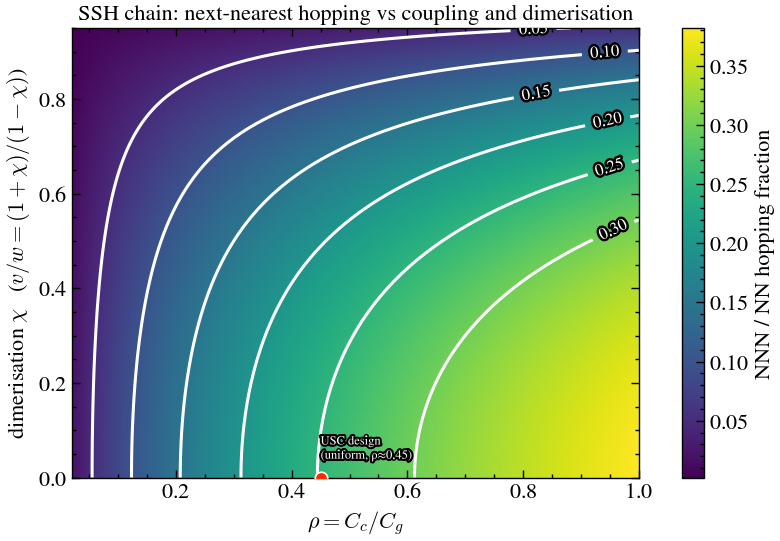

In [14]:
import matplotlib.patheffects as pe

def ssh_nnn_ratio(rho, chi, n_cells=10):
    Ci = np.linalg.inv(ssh_matrix(n_cells, rho, chi, pbc=True))
    m = n_cells
    nn  = 0.5 * (abs(Ci[m, m+1]) + abs(Ci[m, m-1]))
    nnn = 0.5 * (abs(Ci[m, m+2]) + abs(Ci[m, m-2]))
    return nnn / nn

rho_ax = np.linspace(0.02, 1.0, 200)
chi_ax = np.linspace(0.0, 0.95, 200)             # symmetric in chi -> -chi
R, X = np.meshgrid(rho_ax, chi_ax)
Z = np.vectorize(ssh_nnn_ratio)(R, X)

fig, ax = plt.subplots(figsize=(7.8, 5.4), constrained_layout=True)
pcm = ax.pcolormesh(R, X, Z, cmap="viridis", shading="gouraud")   # continuous
fig.colorbar(pcm, ax=ax, label=r"NNN / NN hopping fraction")

cs = ax.contour(R, X, Z, levels=[0.05, 0.10, 0.15, 0.20, 0.25, 0.30],
                colors="w", linewidths=2.2)
for t in ax.clabel(cs, inline=True, fontsize=12, fmt="%.2f"):
    t.set_path_effects([pe.withStroke(linewidth=3.5, foreground="k")])

ax.plot(0.45, 0.0, "o", color="C3", ms=9, mec="w", mew=1.2, zorder=5)
ax.annotate("USC design\n(uniform, ρ≈0.45)", (0.45, 0.04), color="w", fontsize=9,
            path_effects=[pe.withStroke(linewidth=3, foreground="k")])

ax.set_xlabel(r"$\rho = C_c / C_g$")
ax.set_ylabel(r"dimerisation $\chi$   ($v/w = (1+\chi)/(1-\chi)$)")
ax.set_title("SSH chain: next-nearest hopping vs coupling and dimerisation")


Text(0.5, 0.98, 'SSH chain: next-nearest hopping vs coupling and dimerisation')

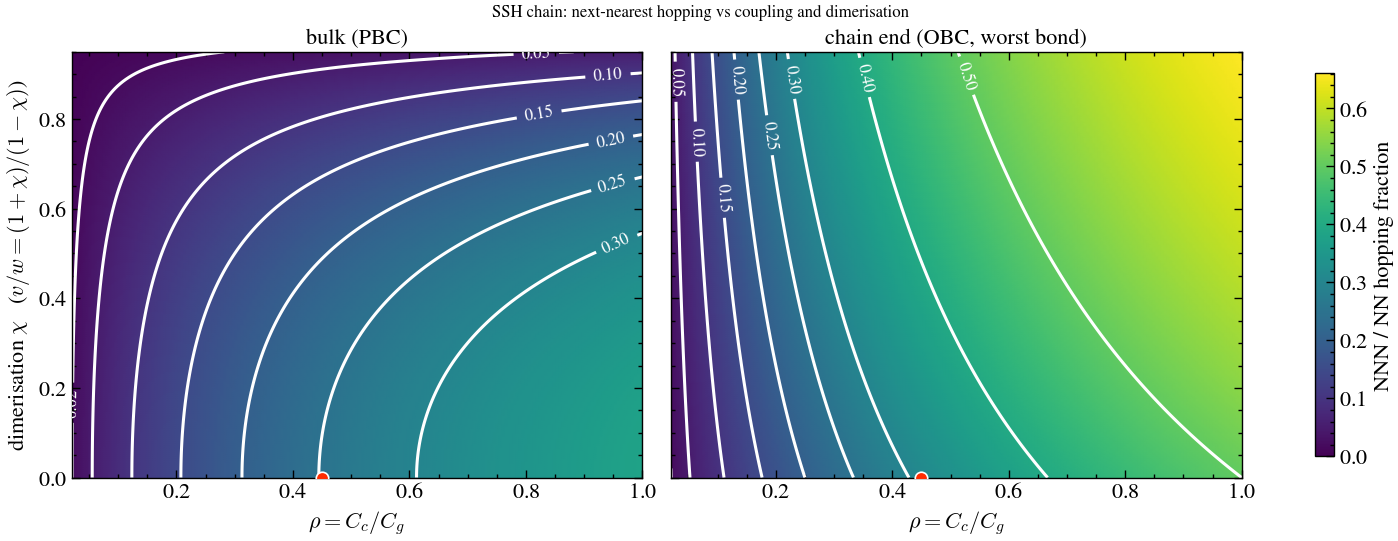

In [15]:
import numpy as np

def ssh_nnn_bulk(rho, chi, n_cells=10):
    Ci = np.linalg.inv(ssh_matrix(n_cells, rho, chi, pbc=True))
    m = n_cells
    nn  = 0.5 * (abs(Ci[m, m+1]) + abs(Ci[m, m-1]))
    nnn = 0.5 * (abs(Ci[m, m+2]) + abs(Ci[m, m-2]))
    return nnn / nn

def ssh_nnn_edge(rho, chi, n_cells=12):
    Ci = np.linalg.inv(ssh_matrix(n_cells, rho, chi, pbc=False))
    d1, d2 = np.diag(Ci, 1), np.diag(Ci, 2)
    return np.max(np.abs(d2 / d1[:len(d2)]))          # worst bond anywhere

rho_ax = np.linspace(0.02, 1.0, 200)
chi_ax = np.linspace(0.0, 0.95, 200)
R, X = np.meshgrid(rho_ax, chi_ax)
Zb = np.vectorize(ssh_nnn_bulk)(R, X)
Ze = np.vectorize(ssh_nnn_edge)(R, X)

vmax = max(Zb.max(), Ze.max())
levels = [0.02, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), constrained_layout=True, sharey=True)
for ax, Z, title in [(axes[0], Zb, "bulk (PBC)"),
                     (axes[1], Ze, "chain end (OBC, worst bond)")]:
    pcm = ax.pcolormesh(R, X, Z, cmap="viridis", shading="gouraud", vmin=0, vmax=vmax)
    cs = ax.contour(R, X, Z, levels=levels, colors="w", linewidths=2.2)
    ax.clabel(cs, inline=True, fontsize=12, fmt="%.2f", colors="w")   # plain white
    ax.plot(0.45, 0.0, "o", color="C3", ms=9, mec="w", mew=1.2, zorder=5)
    ax.set_xlabel(r"$\rho = C_c / C_g$")
    ax.set_title(title)

axes[0].set_ylabel(r"dimerisation $\chi$   ($v/w = (1+\chi)/(1-\chi)$)")
fig.colorbar(pcm, ax=axes, label=r"NNN / NN hopping fraction", shrink=0.9)
fig.suptitle("SSH chain: next-nearest hopping vs coupling and dimerisation")


Text(0.5, 0.98, 'NN vs NNN hopping profiles along an open SSH chain')

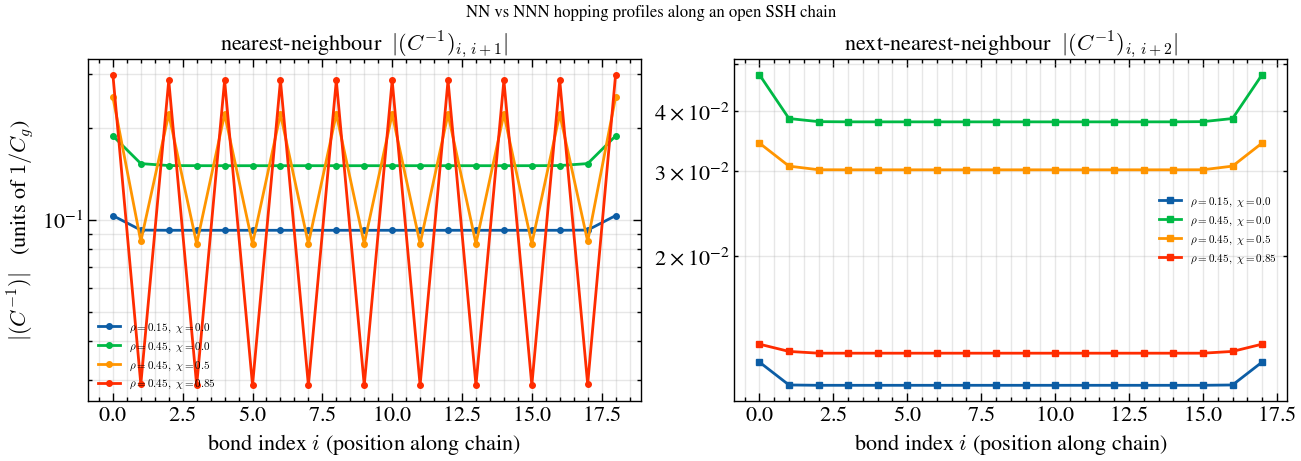

In [16]:
N = 10   # unit cells -> 20 islands, open chain

cases = [
    dict(rho=0.15, chi=0.00),
    dict(rho=0.45, chi=0.00),
    dict(rho=0.45, chi=0.50),
    dict(rho=0.45, chi=0.85),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
for c in cases:
    Ci = np.linalg.inv(ssh_matrix(N, c["rho"], c["chi"], pbc=False))
    nn  = np.abs(np.diag(Ci, 1))    # |(C^-1)_{i,i+1}|, one per NN bond
    nnn = np.abs(np.diag(Ci, 2))    # |(C^-1)_{i,i+2}|, one per NNN pair
    lab = fr"$\rho={c['rho']},\ \chi={c['chi']}$"
    axes[0].plot(np.arange(len(nn)),  nn,  "o-", ms=4, label=lab)
    axes[1].plot(np.arange(len(nnn)), nnn, "s-", ms=4, label=lab)

axes[0].set_title(r"nearest-neighbour  $|(C^{-1})_{i,\,i+1}|$")
axes[1].set_title(r"next-nearest-neighbour  $|(C^{-1})_{i,\,i+2}|$")
for ax in axes:
    ax.set_xlabel("bond index $i$ (position along chain)")
    ax.set_yscale("log")
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$|(C^{-1})|$   (units of $1/C_g$)")
fig.suptitle("NN vs NNN hopping profiles along an open SSH chain")


Text(0.5, 0.98, 'NN vs NNN hopping profiles along an open SSH chain')

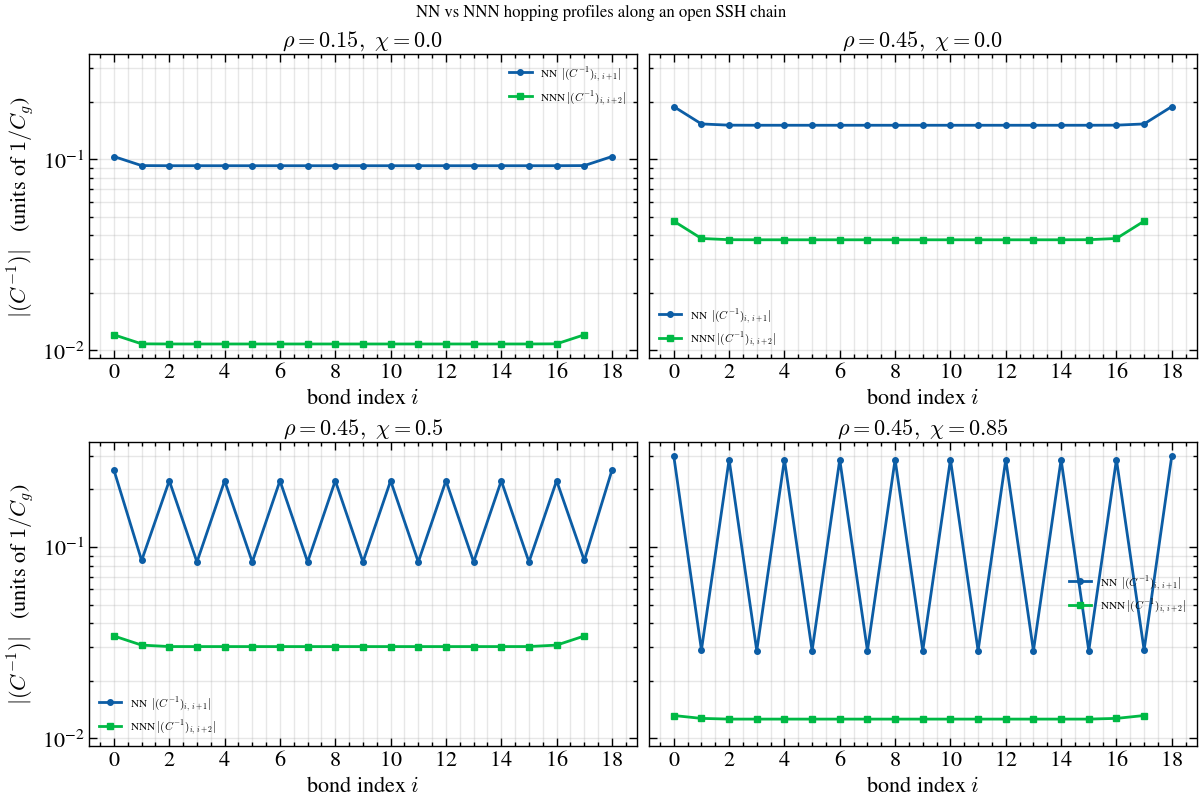

In [17]:
from matplotlib.ticker import MaxNLocator

N = 10   # unit cells -> 20 islands, open chain

cases = [
    dict(rho=0.15, chi=0.00),
    dict(rho=0.45, chi=0.00),
    dict(rho=0.45, chi=0.50),
    dict(rho=0.45, chi=0.85),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True, sharey=True)
for ax, c in zip(axes.flat, cases):
    Ci = np.linalg.inv(ssh_matrix(N, c["rho"], c["chi"], pbc=False))
    nn  = np.abs(np.diag(Ci, 1))     # |(C^-1)_{i,i+1}|, one per NN bond
    nnn = np.abs(np.diag(Ci, 2))     # |(C^-1)_{i,i+2}|, one per NNN pair
    ax.plot(np.arange(len(nn)),  nn,  "o-", ms=4, label=r"NN  $|(C^{-1})_{i,\,i+1}|$")
    ax.plot(np.arange(len(nnn)), nnn, "s-", ms=4, label=r"NNN $|(C^{-1})_{i,\,i+2}|$")
    ax.set_yscale("log")
    ax.set_xlabel("bond index $i$")
    ax.set_title(fr"$\rho={c['rho']},\ \chi={c['chi']}$")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # integer ticks only
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8)

for ax in axes[:, 0]:
    ax.set_ylabel(r"$|(C^{-1})|$   (units of $1/C_g$)")
fig.suptitle("NN vs NNN hopping profiles along an open SSH chain")


Text(0.5, 0.98, 'SSH chain: worst-case NNN vs NN hopping')

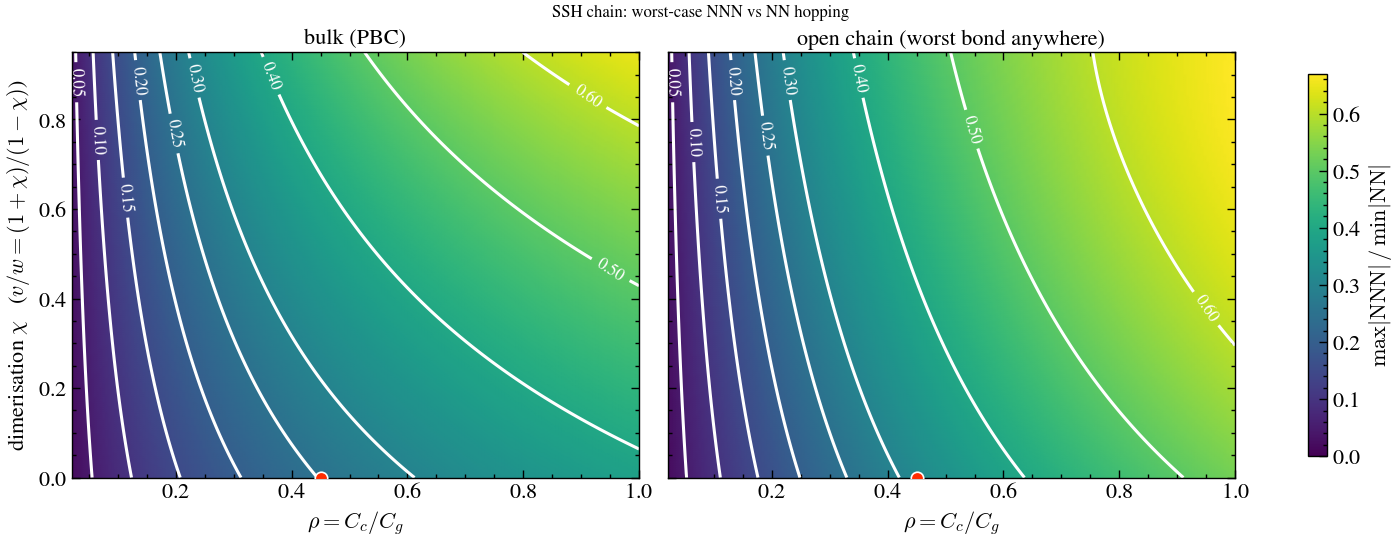

In [18]:
import numpy as np

def _cinv_offdiags(C):
    Ci = np.linalg.inv(C)
    return np.abs(np.diag(Ci, 1)), np.abs(np.diag(Ci, 2))   # NN, NNN

def ssh_worst_bulk(rho, chi, n_cells=20):
    d1, d2 = _cinv_offdiags(ssh_matrix(n_cells, rho, chi, pbc=True))
    w1 = slice(n_cells - 4, n_cells + 5)          # bulk window (NN bonds)
    w2 = slice(n_cells - 4, n_cells + 4)          # bulk window (NNN pairs)
    return d2[w2].max() / d1[w1].min()            # biggest NNN / smallest NN

def ssh_worst_chain(rho, chi, n_cells=14):
    d1, d2 = _cinv_offdiags(ssh_matrix(n_cells, rho, chi, pbc=False))
    return d2.max() / d1.min()                    # worst anywhere in the open chain

rho_ax = np.linspace(0.02, 1.0, 200)
chi_ax = np.linspace(0.0, 0.95, 200)
R, X = np.meshgrid(rho_ax, chi_ax)
Zb = np.vectorize(ssh_worst_bulk)(R, X)
Ze = np.vectorize(ssh_worst_chain)(R, X)

vmax = max(Zb.max(), Ze.max())
levels = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), constrained_layout=True, sharey=True)
for ax, Z, title in [(axes[0], Zb, "bulk (PBC)"),
                     (axes[1], Ze, "open chain (worst bond anywhere)")]:
    pcm = ax.pcolormesh(R, X, Z, cmap="viridis", shading="gouraud", vmin=0, vmax=vmax)
    cs = ax.contour(R, X, Z, levels=levels, colors="w", linewidths=2.2)
    ax.clabel(cs, inline=True, fontsize=12, fmt="%.2f", colors="w")
    ax.plot(0.45, 0.0, "o", color="C3", ms=9, mec="w", mew=1.2, zorder=5)
    ax.set_xlabel(r"$\rho = C_c / C_g$")
    ax.set_title(title)

axes[0].set_ylabel(r"dimerisation $\chi$   ($v/w = (1+\chi)/(1-\chi)$)")
fig.colorbar(pcm, ax=axes, label=r"$\max|{\rm NNN}| \,/\, \min|{\rm NN}|$", shrink=0.9)
fig.suptitle("SSH chain: worst-case NNN vs NN hopping")


Text(0.5, 1.0, 'Circular-pad capacitance  $C = s(g)\\,a + b(g)$   (empirical fit to Palace, $\\varepsilon_r=11.45$)')

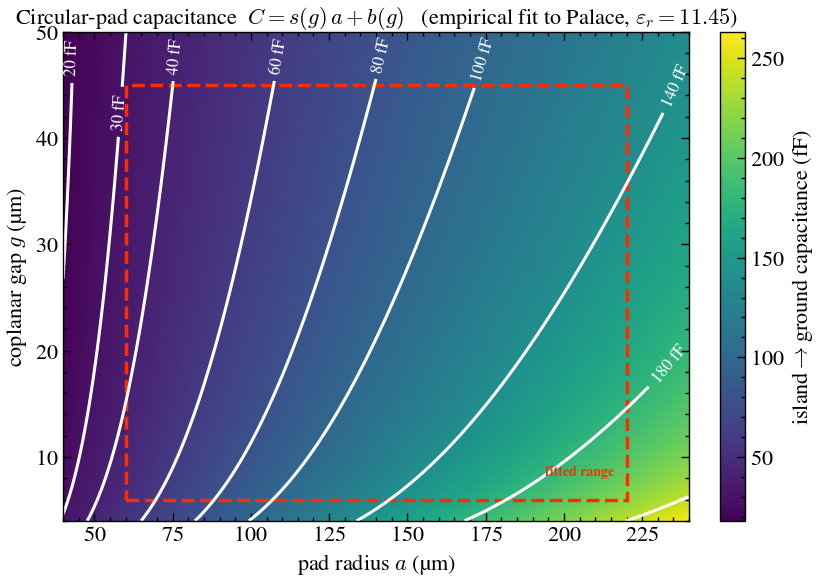

In [19]:
import warnings

# Island->ground capacitance of a circular transmon pad, from the empirical
# fit to Palace electrostatic simulations embedded in DesignHelper
# (see scripts/python/island_cap/island_capacitance_model.md):
#     C = s(g) a + b(g),  s(g) = 1.472 - 0.2235 ln(g),  b(g) = -19.21 + 1.882 sqrt(g)
#     [C in fF, a and g in um, eps_r = 11.45]
# fitted / validated over a in [60, 220] um, g in [6, 45] um.
FIT_A = (60.0, 220.0)     # validated pad-radius range (um)
FIT_G = (6.0, 45.0)       # validated coplanar-gap range (um)

# vectorised wrappers over the (scalar) DesignHelper methods
_C_pad = np.vectorize(lambda a_um, g_um: dh.circular_island_capacitance(a_um, g_um).magnitude)
a_for  = np.vectorize(lambda C_fF, g_um: dh.circular_island_radius_for_capacitance(C_fF, g_um).magnitude)
g_for  = np.vectorize(lambda C_fF, a_um: dh.circular_island_gap_for_capacitance(C_fF, a_um).magnitude)

a_ax = np.linspace(40, 240, 300)     # pad radius, um
g_ax = np.linspace(4, 50, 300)       # coplanar gap, um
A, G = np.meshgrid(a_ax, g_ax)
with warnings.catch_warnings():                       # the grid runs past the
    warnings.simplefilter("ignore")                   # fitted box on purpose
    C = _C_pad(A, G)

fig, ax = plt.subplots(figsize=(8.2, 5.8), constrained_layout=True)
pcm = ax.pcolormesh(A, G, C, cmap="viridis", shading="gouraud")
fig.colorbar(pcm, ax=ax, label=r"island$\to$ground capacitance (fF)")

cs = ax.contour(A, G, C, levels=[20, 30, 40, 60, 80, 100, 140, 180, 240],
                colors="w", linewidths=2.2)
ax.clabel(cs, inline=True, fontsize=12, fmt="%d fF", colors="w")

# outline the range the empirical model was actually fitted / validated over;
# everything outside is extrapolation of the linear-in-a fit
ax.add_patch(plt.Rectangle((FIT_A[0], FIT_G[0]),
                           FIT_A[1] - FIT_A[0], FIT_G[1] - FIT_G[0],
                           fill=False, ec="C3", lw=2.5, ls="--"))
ax.text(FIT_A[1] - 4, FIT_G[0] + 2, "fitted range", color="C3",
        ha="right", va="bottom", fontsize=10, fontweight="bold")

ax.set_xlabel(r"pad radius $a$ (µm)")
ax.set_ylabel(r"coplanar gap $g$ (µm)")
ax.set_title(r"Circular-pad capacitance  $C = s(g)\,a + b(g)$"
             + r"   (empirical fit to Palace, $\varepsilon_r=11.45$)")


# Interdigital coupler capacitance vs geometry

`C_c` of a `CapNInterdigitalRound` coupler between two islands, from the
empirical fit embedded in `DesignHelper`
(see `notebooks/design/transmon_coupler/coupler_capacitance_model.md`):

$$C_c \approx 1.02\,C_{\rm IDC}(\ell-t) + 6.6\ \text{fF},\qquad
C_{\rm IDC}=\varepsilon_0\varepsilon_{\rm eff}(N-1)(\ell-t)\frac{K(k)}{K(k')},\quad
k=\sin\!\tfrac{\pi}{2}\tfrac{w}{w+s}$$

with N = `finger_count`, ℓ = `finger_length`, w = `finger_width`,
s = `finger_gap`, t = `finger_tip_gap`; ℓ − t is the finger overlap.
Fitted over N = 4–16, ℓ = 40–160 µm, s = 3–10 µm, w = 6–12 µm, t = 3–12 µm
(C_c = 21–88 fF, RMS 0.9 fF), for `eps_r = 11.45` and the transmon_coupler lead
routing (60 µm straight neck each side). The colormaps below read off a
geometry for a target C_c; `propose_coupler()` does it numerically.


propose_coupler(30):
 finger_count  finger_length_um  finger_width_um  finger_gap_um  finger_tip_gap_um  C_c_fF
            6              71.1              8.0            4.0                6.0    30.0
            4             114.5              8.0            4.0                6.0    30.0
            8              52.5              8.0            4.0                6.0    30.0


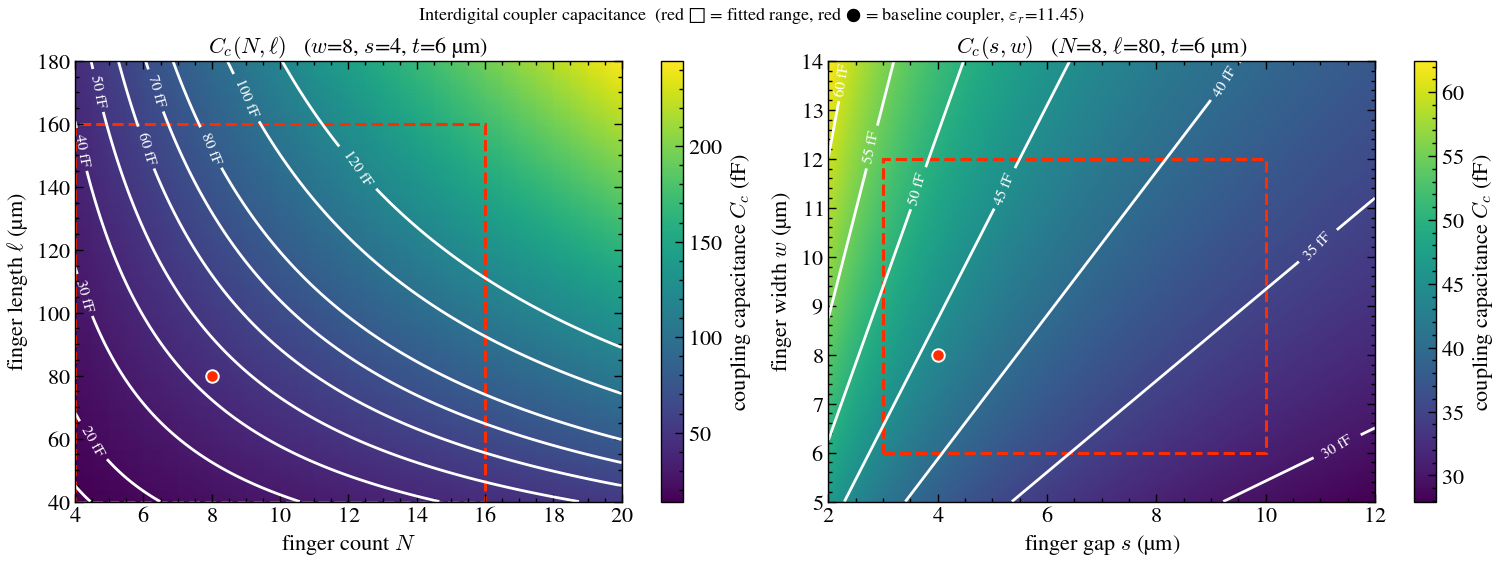

In [20]:
import warnings

# baseline coupler (transmon_coupler / 6-chain): N8, L80, s4, w8, t6 -> ~43.8 fF
CPL_BASE = dict(finger_count=8, finger_length=80.0, finger_width=8.0,
                finger_gap=4.0, finger_tip_gap=6.0)
FIT = dict(N=(4, 16), L=(40, 160), s=(3, 10), w=(6, 12), t=(3, 12))   # validated box

_C_cpl = np.vectorize(
    lambda N, L, w, s, t: dh.interdigital_coupler_capacitance(N, L, w, s, t).magnitude)


def propose_coupler(target_C_c_fF, finger_width=8.0, finger_gap=4.0,
                    finger_tip_gap=6.0, L_range=(45.0, 155.0), n_range=(4, 20)):
    """Geometries (even finger_count, finger_length) hitting a target C_c, using
    the closed-form length inverse. Returns a DataFrame sorted by |L - 90 um|
    (prefer a mid-range finger length)."""
    rows = []
    for N in range(n_range[0], n_range[1] + 1, 2):
        try:
            L = dh.interdigital_coupler_finger_length_for_capacitance(
                f"{target_C_c_fF}fF", N, finger_width, finger_gap, finger_tip_gap).magnitude
        except ValueError:
            continue
        if L_range[0] <= L <= L_range[1]:
            Cc = dh.interdigital_coupler_capacitance(
                N, L, finger_width, finger_gap, finger_tip_gap).magnitude
            rows.append(dict(finger_count=N, finger_length_um=round(L, 1),
                             finger_width_um=finger_width, finger_gap_um=finger_gap,
                             finger_tip_gap_um=finger_tip_gap, C_c_fF=round(Cc, 2)))
    return pd.DataFrame(rows).sort_values(
        "finger_length_um", key=lambda s: (s - 90).abs()).reset_index(drop=True)


# ---- colormaps: C_c over the two most useful 2D slices ----
N_ax = np.arange(4, 21)                       # finger count (even design values)
L_ax = np.linspace(40, 180, 240)             # finger length (um)
s_ax = np.linspace(2, 12, 240)               # finger gap (um)
w_ax = np.linspace(5, 14, 240)               # finger width (um)

NN, LL = np.meshgrid(N_ax, L_ax)
SS, WW = np.meshgrid(s_ax, w_ax)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")          # grids run past the fitted box on purpose
    C_NL = _C_cpl(NN, LL, CPL_BASE["finger_width"], CPL_BASE["finger_gap"], CPL_BASE["finger_tip_gap"])
    C_sw = _C_cpl(CPL_BASE["finger_count"], CPL_BASE["finger_length"], WW, SS, CPL_BASE["finger_tip_gap"])

levels = [15, 20, 30, 40, 50, 60, 70, 80, 100, 120]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), constrained_layout=True)

pcm = ax[0].pcolormesh(NN, LL, C_NL, cmap="viridis", shading="gouraud")
fig.colorbar(pcm, ax=ax[0], label=r"coupling capacitance $C_c$ (fF)")
cs = ax[0].contour(NN, LL, C_NL, levels=levels, colors="w", linewidths=2.0)
ax[0].clabel(cs, inline=True, fontsize=11, fmt="%d fF", colors="w")
ax[0].add_patch(plt.Rectangle((FIT["N"][0], FIT["L"][0]), FIT["N"][1] - FIT["N"][0],
                              FIT["L"][1] - FIT["L"][0], fill=False, ec="C3", lw=2.2, ls="--"))
ax[0].plot(CPL_BASE["finger_count"], CPL_BASE["finger_length"], "o", color="C3", ms=9, mec="w", mew=1.4)
ax[0].set_xlabel("finger count $N$"); ax[0].set_ylabel(r"finger length $\ell$ (µm)")
ax[0].set_title(f"$C_c(N,\\ell)$   ($w$={CPL_BASE['finger_width']:.0f}, $s$={CPL_BASE['finger_gap']:.0f}, "
                f"$t$={CPL_BASE['finger_tip_gap']:.0f} µm)")

pcm = ax[1].pcolormesh(SS, WW, C_sw, cmap="viridis", shading="gouraud")
fig.colorbar(pcm, ax=ax[1], label=r"coupling capacitance $C_c$ (fF)")
cs = ax[1].contour(SS, WW, C_sw, levels=[25, 30, 35, 40, 45, 50, 55, 60], colors="w", linewidths=2.0)
ax[1].clabel(cs, inline=True, fontsize=11, fmt="%d fF", colors="w")
ax[1].add_patch(plt.Rectangle((FIT["s"][0], FIT["w"][0]), FIT["s"][1] - FIT["s"][0],
                              FIT["w"][1] - FIT["w"][0], fill=False, ec="C3", lw=2.2, ls="--"))
ax[1].plot(CPL_BASE["finger_gap"], CPL_BASE["finger_width"], "o", color="C3", ms=9, mec="w", mew=1.4)
ax[1].set_xlabel("finger gap $s$ (µm)"); ax[1].set_ylabel(r"finger width $w$ (µm)")
ax[1].set_title(f"$C_c(s,w)$   ($N$={CPL_BASE['finger_count']}, $\\ell$={CPL_BASE['finger_length']:.0f}, "
                f"$t$={CPL_BASE['finger_tip_gap']:.0f} µm)")

fig.suptitle("Interdigital coupler capacitance  (red □ = fitted range, red ● = baseline coupler, "
             r"$\varepsilon_r$=11.45)", fontsize=13)

# example: geometries for a 30 fF coupler
print("propose_coupler(30):")
print(propose_coupler(30).to_string(index=False))
